# 04 · Les postes qui peinent à recruter

Le plan prévoyait un modèle du salaire. Le service public ne publie pas de salaire dans ses offres : cette étape prend
une cible de repli qui dit, elle aussi, quelque chose du marché. Quand un employeur **remet en ligne le même poste**
quelques semaines ou mois plus tard, c'est en général qu'il n'a pas trouvé. On appelle donc **republiée** une annonce
dont le poste (même organisme, même métier, même intitulé, même département) revient entre 7 et 180 jours après. Sous
7 jours, c'est plutôt un doublon ou une correction ; au-delà de 6 mois, plutôt un nouveau recrutement.

Questions :
1. Quels postes sont le plus souvent republiés, et cette part évolue-t-elle ?
2. Peut-on prévoir, le jour de la publication, qu'une annonce sera republiée ?
3. Qu'est-ce qui rend un poste difficile à pourvoir, toutes choses égales par ailleurs (SHAP) ?
4. Certaines compétences demandées vont-elles avec plus de republications ?

Limites de la cible : un employeur qui recrute plusieurs fois le même poste pour des postes différents (un CHU qui
embauche des infirmiers de nuit toute l'année) compte comme une republication ; un poste pourvu par une autre voie
(mutation, concours) sans nouvelle annonce n'en compte pas. C'est un indicateur de tension, pas une mesure exacte.

In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import polars as pl
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score

from offres import donnees, recrutement as rec
from offres import graphiques as g

g.style()
pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(80)
POURCENT = mtick.FuncFormatter(lambda v, _: f"{v:.0%}".replace("%", " %"))
offres = donnees.offres_service_public()
a = rec.republications(offres).with_columns(annee=pl.col("date_publication").dt.year())
print(f"{a.height:,} annonces publiées du {a['date_publication'].min()} au {a['date_publication'].max()} "
      f"(les plus récentes sont écartées : on ne sait pas encore si elles reviendront)")
print(f"Republiées : {a['republiee'].mean():.1%}")
a.group_by("annee").agg(annonces=pl.len(), republiees=pl.col("republiee").mean()).sort("annee")

1,403,059 annonces publiées du 2022-01-02 au 2026-03-31 (les plus récentes sont écartées : on ne sait pas encore si elles reviendront)
Republiées : 12.4%


annee,annonces,republiees
i32,u32,f64
2022,294824,0.108706
2023,331763,0.111724
2024,344911,0.128996
2025,345224,0.140752
2026,86337,0.143936


## 1. Qui republie ?

shape: (4, 3)
┌────────────────────────────────┬──────────┬────────────┐
│ versant                        ┆ annonces ┆ republiees │
│ ---                            ┆ ---      ┆ ---        │
│ str                            ┆ u32      ┆ f64        │
╞════════════════════════════════╪══════════╪════════════╡
│ null                           ┆ 6357     ┆ 0.188296   │
│ Fonction Publique Territoriale ┆ 858342   ┆ 0.136853   │
│ Fonction Publique Hospitalière ┆ 85106    ┆ 0.10924    │
│ Fonction Publique de l'Etat    ┆ 453254   ┆ 0.102953   │
└────────────────────────────────┴──────────┴────────────┘
shape: (5, 3)
┌───────────┬──────────┬────────────┐
│ categorie ┆ annonces ┆ republiees │
│ ---       ┆ ---      ┆ ---        │
│ str       ┆ u32      ┆ f64        │
╞═══════════╪══════════╪════════════╡
│ C         ┆ 548727   ┆ 0.152602   │
│ B         ┆ 346346   ┆ 0.116164   │
│ A         ┆ 456322   ┆ 0.102743   │
│ A+        ┆ 34580    ┆ 0.077646   │
│ null      ┆ 17084    ┆ 0.063568   │
└─

232 métiers d'au moins 1 000 annonces


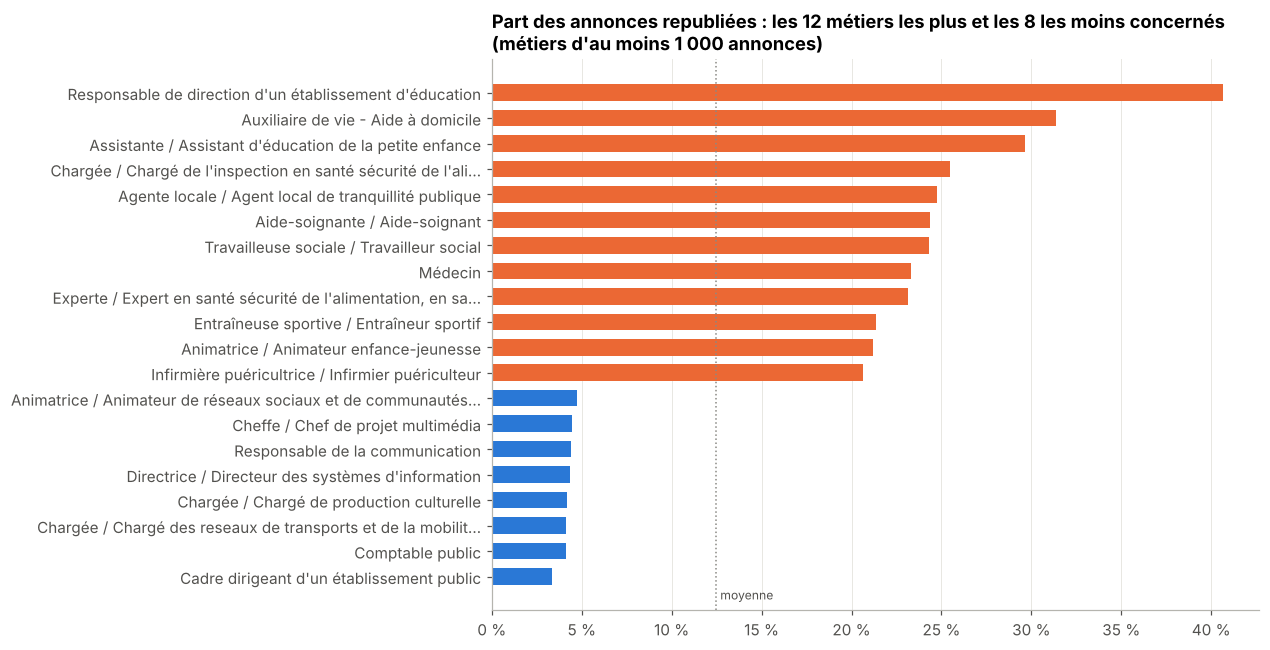

In [2]:
par = lambda col: (a.group_by(col).agg(annonces=pl.len(), republiees=pl.col("republiee").mean())
                   .filter(pl.col("annonces") >= 1000).sort("republiees", descending=True))
print(par("versant"))
print(par("categorie"))
metiers = par("metier")
extremes = pl.concat([metiers.head(12), metiers.tail(8)])
fig, ax = plt.subplots(figsize=(9, 6.5))
ordre = extremes.reverse()
couleurs = [g.PALETTE[1] if r > a["republiee"].mean() else g.PALETTE[0] for r in ordre["republiees"]]
ax.barh([m if len(m) <= 60 else m[:59] + "…" for m in ordre["metier"]], ordre["republiees"], color=couleurs, height=0.65)
ax.axvline(a["republiee"].mean(), color=g.GRIS, lw=1, ls=":")
ax.annotate("moyenne", (a["republiee"].mean(), -0.9), xytext=(3, 0), textcoords="offset points", fontsize=8, color="#52514e")
ax.xaxis.set_major_formatter(POURCENT)
ax.grid(axis="y", visible=False)
ax.set_title("Part des annonces republiées : les 12 métiers les plus et les 8 les moins concernés\n(métiers d'au moins 1 000 annonces)")
g.enregistrer(fig, "19_republication_metiers")
print(f"{metiers.height} métiers d'au moins 1 000 annonces")

In [3]:
# Robustesse de la définition : le classement des métiers change-t-il avec la fenêtre ?
taux = {}
for lo, hi in [(7, 90), (7, 180), (30, 365)]:
    b = rec.republications(offres, lo, hi)
    taux[(lo, hi)] = b.group_by("metier").agg(r=pl.col("republiee").mean(), n=pl.len()).filter(pl.col("n") >= 1000)
ref = taux[(7, 180)]
for k in [(7, 90), (30, 365)]:
    j = ref.join(taux[k], on="metier")
    print(f"Fenêtre {k[0]}-{k[1]} jours : corrélation de rang avec 7-180 jours = {spearmanr(j['r'], j['r_right']).statistic:.2f} "
          f"({j.height} métiers)")

Fenêtre 7-90 jours : corrélation de rang avec 7-180 jours = 0.94 (232 métiers)
Fenêtre 30-365 jours : corrélation de rang avec 7-180 jours = 0.92 (219 métiers)


Un peu plus d'une annonce sur huit est republiée, et la part monte d'année en année : 10,9 % en 2022, 14,1 % en 2025.
La territoriale republie plus (13,7 %) que l'hôpital et l'État (10 à 11 %), et la catégorie C (15,3 %) plus que la A+
(7,8 %). En tête viennent des métiers réputés difficiles à pourvoir : aide à domicile, petite enfance, aides-soignants,
travailleurs sociaux, médecins, puéricultrices, avec 20 à 31 % d'annonces republiées. En bas, la communication, la
culture, les directions des systèmes d'information et les cadres dirigeants (moins de 5 %). Le premier métier, les
directions d'établissement d'éducation (40 %), tient peut-être en partie au calendrier des nominations plutôt qu'à une
pénurie : à vérifier.

Le classement des métiers ne dépend guère de la fenêtre choisie : il est corrélé à 0,94 avec une fenêtre de 7 à 90
jours et à 0,92 avec une fenêtre de 30 à 365 jours.

## 2. Prévoir la republication le jour de la publication

Le modèle (LightGBM) apprend sur les annonces de 2022 à 2024 et il est évalué sur celles de 2025 et du début 2026, comme
s'il servait sur les annonces à venir. Il ne voit que ce que l'on sait le jour de la publication : métier, département,
organisme, versant, catégorie, nature de l'emploi, statut du poste, expérience, télétravail, management, temps plein,
niveau d'études, mois, nombre de postes, présence d'un texte de compétences, et l'**historique du poste** (déjà
republié dans les 6 mois précédents, nombre de publications antérieures). On le compare à deux règles simples : le
taux de republication du métier, et celui du couple métier × département, appris sur 2022-2024.

In [4]:
app, test = a.filter(pl.col("annee") <= 2024), a.filter(pl.col("annee") >= 2025)
X_app = rec.variables(app)
X_test = rec.aligner(rec.variables(test), X_app)
y_app, y_test = app["republiee"].to_numpy(), test["republiee"].to_numpy()
PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=63, min_child_samples=100, cat_smooth=50, cat_l2=10,
              max_cat_to_onehot=8, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, verbose=-1, seed=0,
              num_threads=4)
def evaluer(nom, p):
    haut = p >= np.quantile(p, 0.9)
    return {"modele": nom, "auc": roc_auc_score(y_test, p), "precision_moyenne": average_precision_score(y_test, p),
            "republiees_dans_le_decile_haut": y_test[haut].mean()}
resultats = []
for cols, nom in [(["metier"], "taux du métier"), (["metier", "departement"], "taux métier × département")]:
    prior = y_app.mean()
    t = (app.group_by(cols).agg(r=pl.col("republiee").sum(), n=pl.len())
         .with_columns(r=(pl.col("r") + 20 * prior) / (pl.col("n") + 20)))  # lissé vers la moyenne
    resultats.append(evaluer(nom, test.join(t, on=cols, how="left")["r"].fill_null(prior).to_numpy()))
modeles = {}
TOUT = rec.CATEGORIELLES + rec.NUMERIQUES
for nom, cols in [("LightGBM sans historique", [c for c in TOUT if c not in ("deja_republiee", "publications_avant")]),
                  ("LightGBM sans organisme", [c for c in TOUT if c != "organisme"]),
                  ("LightGBM complet", TOUT)]:
    modeles[nom] = (lgb.train(PARAMS, lgb.Dataset(X_app[cols], y_app), 600), cols)
    resultats.append(evaluer(nom, modeles[nom][0].predict(X_test[cols])))
print(f"Part republiée sur la période de test : {y_test.mean():.1%}")
pl.DataFrame(resultats)

Part republiée sur la période de test : 14.1%


modele,auc,precision_moyenne,republiees_dans_le_decile_haut
str,f64,f64,f64
"""taux du métier""",0.653444,0.231796,0.276758
"""taux métier × département""",0.67673,0.274069,0.344932
"""LightGBM sans historique""",0.722724,0.310462,0.387793
"""LightGBM sans organisme""",0.760881,0.394276,0.484834
"""LightGBM complet""",0.764281,0.395187,0.48553


d,prevu,observe
i64,f64,f64
0,0.027799,0.035823
1,0.042069,0.047131
2,0.053998,0.059551
3,0.06641,0.069446
4,0.080771,0.078019
5,0.098864,0.096325
6,0.126193,0.114978
7,0.175888,0.165933
8,0.279935,0.261841


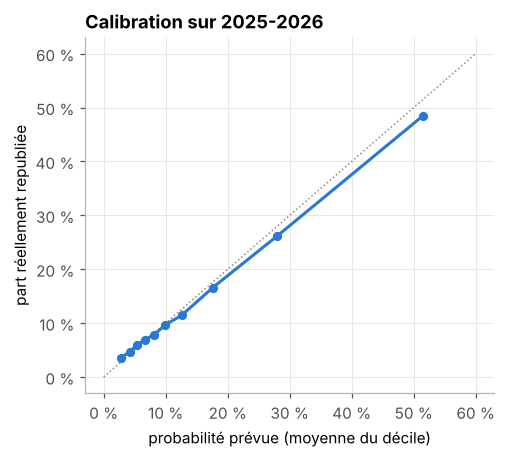

In [5]:
MODELE = "LightGBM sans organisme"
modele, COLS = modeles[MODELE]
p_test = modele.predict(X_test[COLS])
rang = np.argsort(np.argsort(p_test))
deciles = pl.DataFrame({"p": p_test, "y": y_test, "d": rang * 10 // len(p_test)})
cal = deciles.group_by("d").agg(prevu=pl.col("p").mean(), observe=pl.col("y").mean()).sort("prevu")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot([0, 0.6], [0, 0.6], color=g.GRIS, lw=1, ls=":")
ax.plot(cal["prevu"], cal["observe"], "-o", color=g.PALETTE[0], ms=5)
ax.xaxis.set_major_formatter(POURCENT)
ax.yaxis.set_major_formatter(POURCENT)
ax.set_xlabel("probabilité prévue (moyenne du décile)")
ax.set_ylabel("part réellement republiée")
ax.set_title("Calibration sur 2025-2026")
g.enregistrer(fig, "20_calibration_republication")
cal

Le modèle complet atteint une AUC de 0,76 sur 2025-2026, contre 0,65 pour le seul taux du métier et 0,68 pour le taux
métier × département. Le décile d'annonces qu'il juge les plus à risque contient 48 % d'annonces republiées, contre
14 % en moyenne et 34 % avec la meilleure règle simple. L'**historique du poste** apporte le plus (AUC 0,72 sans lui) :
un poste déjà publié plusieurs fois a plus de chances de l'être encore. L'organisme n'ajoute presque rien (0,764 contre
0,761) ; on garde donc le modèle sans organisme, plus simple à expliquer. Ses probabilités sont bien calibrées : dans
chaque décile, la part prévue est proche de la part observée (51 % prévus, 48 % observés dans le dernier).

## 3. Ce qui rend un poste difficile à pourvoir

Les valeurs SHAP décomposent chaque prévision en contributions des variables (en log-cote : + 0,1 multiplie à peu près
la cote de republication par 1,1). Leur moyenne par modalité dit l'effet d'une caractéristique **à métier, lieu et
autres caractéristiques donnés**, ce que les taux bruts de la partie 1 ne font pas. On les calcule sur 100 000 annonces
de la période de test.

variable,shap_moyen_abs
str,f64
"""publications_avant""",0.460125
"""metier""",0.304491
"""departement""",0.202848
"""categorie""",0.072485
"""mois""",0.062761
"""versant""",0.054646
"""temps_plein""",0.052007
"""deja_republiee""",0.051163
"""management""",0.047739


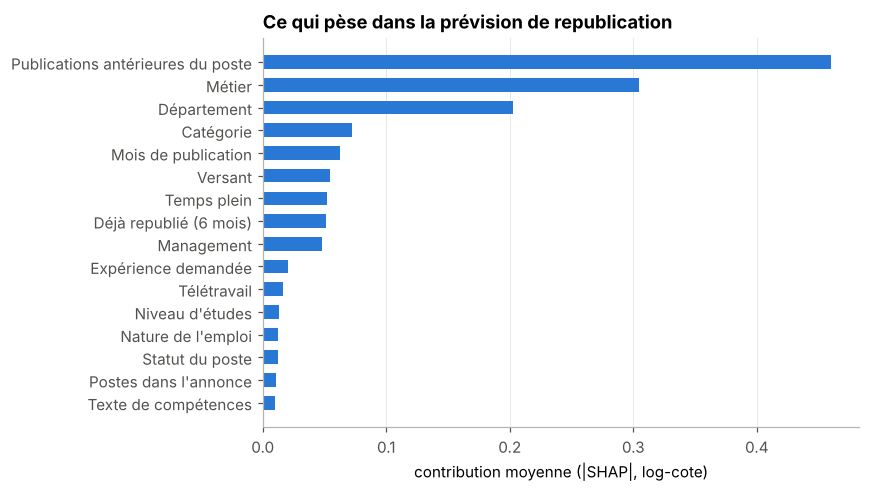

In [6]:
rng = np.random.default_rng(0)
idx = rng.choice(len(X_test), 100_000, replace=False)
Xs = X_test[COLS].iloc[idx]
contrib = modele.predict(Xs, pred_contrib=True)[:, :-1]
importance = pl.DataFrame({"variable": COLS, "shap_moyen_abs": np.abs(contrib).mean(axis=0)}).sort("shap_moyen_abs", descending=True)
NOMS = {"metier": "Métier", "departement": "Département", "publications_avant": "Publications antérieures du poste",
        "deja_republiee": "Déjà republié (6 mois)", "mois": "Mois de publication", "categorie": "Catégorie",
        "versant": "Versant", "nature_emploi": "Nature de l'emploi", "statut_poste": "Statut du poste",
        "experience": "Expérience demandée", "teletravail": "Télétravail", "management": "Management",
        "temps_plein": "Temps plein", "niveau_etudes": "Niveau d'études", "postes_annonce": "Postes dans l'annonce",
        "texte_competences": "Texte de compétences", "organisme": "Organisme"}
fig, ax = plt.subplots(figsize=(7, 4.6))
imp = importance.reverse()
ax.barh([NOMS[v] for v in imp["variable"]], imp["shap_moyen_abs"], color=g.PALETTE[0], height=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("contribution moyenne (|SHAP|, log-cote)")
ax.set_title("Ce qui pèse dans la prévision de republication")
g.enregistrer(fig, "21_importance_republication")
importance

categorie [('C', 0.086, 40668), ('B', 0.029, 23837), ('A', -0.064, 31655), ('A+', -0.188, 2220)]
nature_emploi [("Emploi réservé aux fonctionnaires et lauréats d'un concours territorial", 0.021, 1588), ('Emploi ouvert aux titulaires et aux contractuels', 0.005, 84005), ('Emploi ouvert uniquement aux contractuels', -0.027, 14167)]
statut_poste [("Susceptible d'être vacant", 0.029, 5109), ('Vacant', -0.002, 90691)]
experience [('Débutant', 0.045, 7111), ('Confirmé', -0.022, 20894), ('Expert', -0.202, 2160)]
teletravail [(0.0, 0.016, 29888), (1.0, -0.005, 18006)]
management [(0.0, 0.009, 39689), (1.0, -0.216, 10927)]
temps_plein [(1.0, 0.033, 78820), (0.0, -0.06, 12478)]


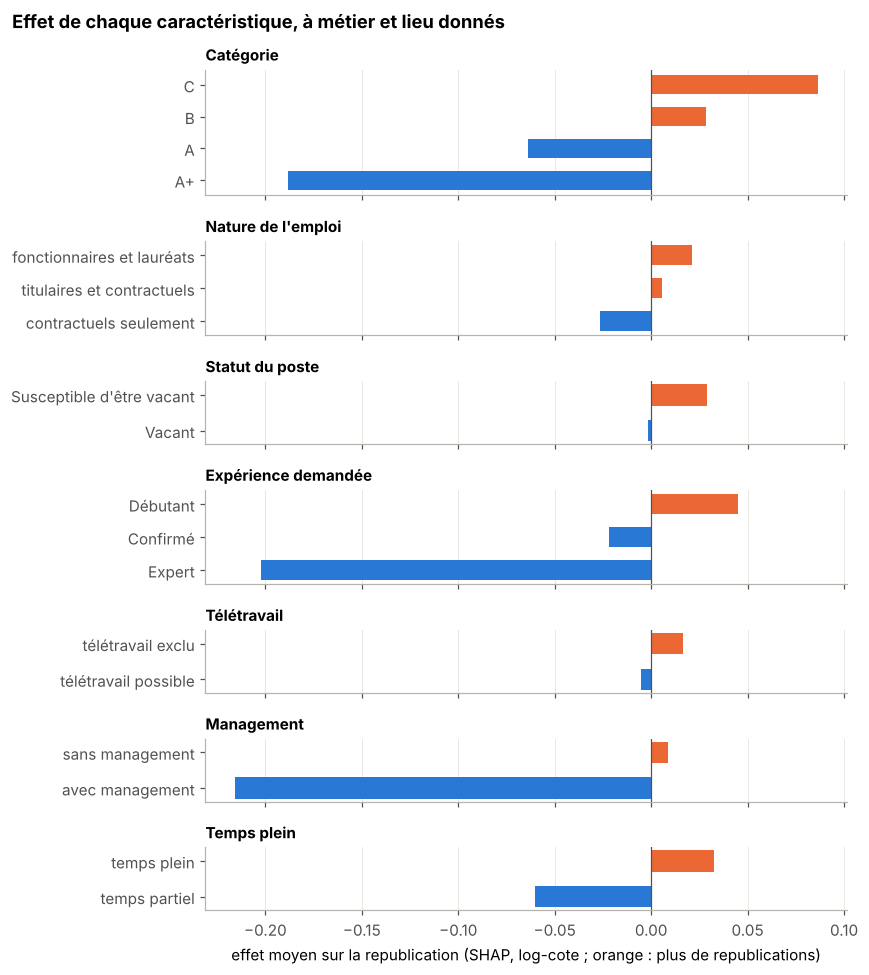

In [7]:
S = pl.DataFrame({c: contrib[:, i] for i, c in enumerate(COLS)})
V = pl.from_pandas(Xs.reset_index(drop=True).astype({c: str for c in rec.CATEGORIELLES if c in COLS}))
def effet(col, min_n=500):
    return (pl.DataFrame({"modalite": V[col], "shap": S[col]}).drop_nulls("modalite")
            .group_by("modalite").agg(shap=pl.col("shap").mean(), n=pl.len()).filter(pl.col("n") >= min_n)
            .sort("shap", descending=True))
LIBELLES = {"teletravail": {1.0: "télétravail possible", 0.0: "télétravail exclu"},
            "management": {1.0: "avec management", 0.0: "sans management"},
            "temps_plein": {1.0: "temps plein", 0.0: "temps partiel"},
            "nature_emploi": {"Emploi réservé aux fonctionnaires et lauréats d'un concours territorial": "fonctionnaires et lauréats",
                              "Emploi ouvert aux titulaires et aux contractuels": "titulaires et contractuels",
                              "Emploi ouvert uniquement aux contractuels": "contractuels seulement"}}
blocs = ["categorie", "nature_emploi", "statut_poste", "experience", "teletravail", "management", "temps_plein"]
fig, axes = plt.subplots(len(blocs), 1, figsize=(8, 9), sharex=True,
                         gridspec_kw={"height_ratios": [max(2, effet(c).height) for c in blocs]})
for ax, col in zip(axes, blocs):
    e = effet(col).reverse()
    noms = [LIBELLES.get(col, {}).get(float(m) if col in ("teletravail", "management", "temps_plein") else m, str(m))
            for m in e["modalite"]]
    ax.barh(noms, e["shap"], color=[g.PALETTE[1] if v > 0 else g.PALETTE[0] for v in e["shap"]], height=0.6)
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_title(NOMS[col], fontsize=10, loc="left")
    ax.grid(axis="y", visible=False)
axes[-1].set_xlabel("effet moyen sur la republication (SHAP, log-cote ; orange : plus de republications)")
fig.suptitle("Effet de chaque caractéristique, à métier et lieu donnés", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
g.enregistrer(fig, "22_effets_republication")
for col in blocs:
    print(col, [(m, round(v, 3), n) for m, v, n in effet(col).iter_rows()])

Métiers, effet propre le plus fort : [("Responsable de direction d'un établissement d'éducation", 1.31), ('Aide-soignante / Aide-soignant', 0.78), ('Auxiliaire de vie - Aide à domicile', 0.76), ("Assistante / Assistant d'éducation de la petite enfance", 0.75), ('Assistante / Assistant de service social', 0.58), ('Médecin', 0.57), ('Éducatrice / Educateur de jeunes enfants', 0.56), ('Agente locale / Agent local de tranquillité publique', 0.55)]
Métiers, effet propre le plus faible : [('Technicienne / Technicien du spectacle', -0.46), ('Bibliothécaire', -0.48), ("Chargée / Chargé d'animation auprès des publics", -0.51), ('Chargée / Chargé de bibliothèque', -0.59), ('Chargée / Chargé de politique environnementale', -0.61)]


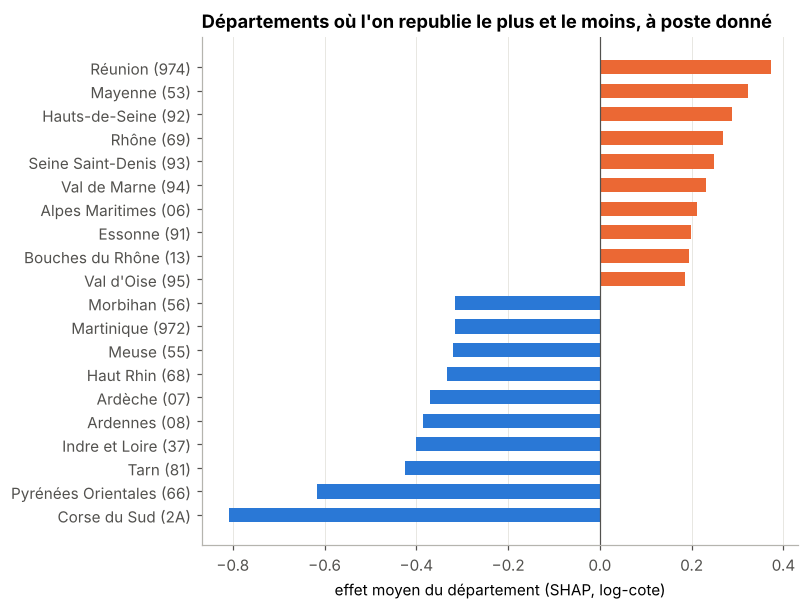

In [8]:
dep = effet("departement", min_n=300)
noms_dep = dict(offres.select("departement", "departement_nom").drop_nulls().unique("departement").iter_rows())
extremes = pl.concat([dep.head(10), dep.tail(10)]).with_columns(nom=pl.col("modalite").replace_strict(noms_dep, default=pl.col("modalite")))
fig, ax = plt.subplots(figsize=(7, 6))
e = extremes.reverse()
ax.barh([f"{n} ({c})" for n, c in zip(e["nom"], e["modalite"])], e["shap"],
        color=[g.PALETTE[1] if v > 0 else g.PALETTE[0] for v in e["shap"]], height=0.6)
ax.axvline(0, color="#52514e", lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("effet moyen du département (SHAP, log-cote)")
ax.set_title("Départements où l'on republie le plus et le moins, à poste donné")
g.enregistrer(fig, "23_departements_republication")
mt = effet("metier", min_n=300)
print("Métiers, effet propre le plus fort :", [(m, round(v, 2)) for m, v, _ in mt.head(8).iter_rows()])
print("Métiers, effet propre le plus faible :", [(m, round(v, 2)) for m, v, _ in mt.tail(5).iter_rows()])

L'historique du poste, le métier et le département pèsent le plus ; viennent ensuite la catégorie, le mois, le versant
et les conditions du poste. À métier et lieu donnés :
- les postes de **catégorie C** et pour **débutants** sont plus souvent republiés, ceux de **catégorie A+**, pour
  **experts** ou **avec management** beaucoup moins (- 0,19 à - 0,22 en log-cote, soit une cote réduite d'environ 20 %) ;
- le **temps plein** est un peu plus souvent republié que le temps partiel, contrairement à l'intuition ; le
  **télétravail** possible et l'ouverture aux **contractuels** vont avec un peu moins de republications, mais ces effets
  sont faibles (moins de 0,03).

À poste donné, on republie le plus à La Réunion, en Mayenne et dans plusieurs départements urbains (Hauts-de-Seine,
Rhône, Seine-Saint-Denis, Val-de-Marne, Alpes-Maritimes, Bouches-du-Rhône) ; le moins en Corse-du-Sud, dans les
Pyrénées-Orientales, le Tarn ou l'Indre-et-Loire. Ces écarts mêlent tension réelle et habitudes de publication des
employeurs locaux, que le modèle ne sait pas séparer. Parmi les métiers, l'effet propre le plus fort reste celui des
directions d'établissement d'éducation, puis des aides-soignants, des aides à domicile et de la petite enfance.

## 4. Les compétences demandées

Le texte de compétences n'existe que pour une annonce sur vingt, surtout à l'État : on ne l'a pas mis dans le modèle.
On regarde à part, sur les annonces de test qui en ont un, si certaines compétences vont avec plus de republications
**que ce que prévoit le modèle** pour ce poste (métier, lieu, organisme, conditions) : l'écart moyen entre republication observée
et prévue, par compétence citée dans au moins 150 de ces annonces, avec un intervalle à 95 %.

16,637 annonces de test avec des compétences ; écart moyen observé - prévu : -0.011 (retiré)
105 compétences testées, 26 dont l'intervalle exclut 0


forme,n,ecart,marge,net
str,u32,f64,f64,bool
"""estimation des couts d une operation d infrastructure""",200,0.095118,0.053221,true
"""principes et regles necessaires a la bonne execution financiere des marches publ…",186,0.093496,0.053897,true
"""regles et procedures d execution de la depense""",219,0.092806,0.052374,true
"""regles de realisation d une operation d infra""",191,0.079028,0.052614,true
"""reglementation et jurisprudence de la commande publique""",500,0.072943,0.030787,true
"""regles du marche public de travaux""",346,0.057887,0.038053,true
"""esprit d equipe""",298,0.056024,0.035682,true
"""animation d un groupe de travail""",165,0.047434,0.04393,true
"""systemes d information financiere et des technologies numeriques associees""",201,0.043461,0.044824,false


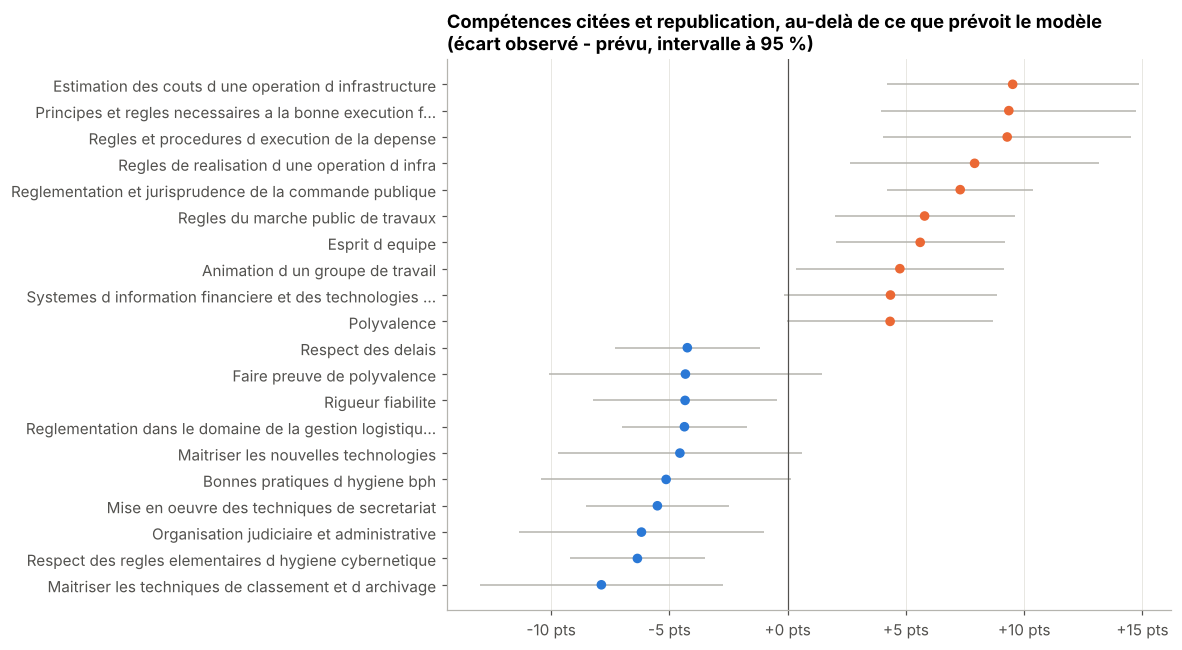

In [9]:
items = pl.read_parquet(donnees.chemin("competences_items.parquet")).unique(["annonce_id", "forme"])
# Modèle complet (organisme compris) : l'écart ne doit pas refléter seulement l'employeur qui rédige le texte
complet, cols_complet = modeles["LightGBM complet"]
residu = test.select("annonce_id").with_columns(ecart=pl.Series(y_test - complet.predict(X_test[cols_complet])))
residu = residu.filter(pl.col("annonce_id").is_in(items["annonce_id"].unique().implode()))
# Le modèle surestime un peu la republication des annonces avec texte : on centre l'écart sur ces annonces
print(f"{residu.height:,} annonces de test avec des compétences ; écart moyen observé - prévu : {residu['ecart'].mean():+.3f} (retiré)")
residu = residu.with_columns(ecart=pl.col("ecart") - pl.col("ecart").mean())
avec = residu.join(items, on="annonce_id")
par_forme = (avec.group_by("forme").agg(n=pl.len(), ecart=pl.col("ecart").mean(), sd=pl.col("ecart").std())
             .filter(pl.col("n") >= 150).with_columns(marge=1.96 * pl.col("sd") / pl.col("n").sqrt())
             .with_columns(net=(pl.col("ecart").abs() > pl.col("marge"))).sort("ecart", descending=True))
print(f"{par_forme.height} compétences testées, {par_forme['net'].sum()} dont l'intervalle exclut 0")
graphies = pl.read_parquet(donnees.chemin("competences_formes.parquet")) if "libelle" in pl.read_parquet_schema(donnees.chemin("competences_formes.parquet")) else None
LIB = dict(graphies.select("forme", "libelle").iter_rows()) if graphies is not None else {}
def lib(f, n=55):
    t = LIB.get(f, f)
    t = t[0].upper() + t[1:]
    return t if len(t) <= n else t[: n - 1] + "…"
ext = pl.concat([par_forme.head(10), par_forme.tail(10)]).reverse()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.errorbar(ext["ecart"], range(ext.height), xerr=ext["marge"], fmt="none", ecolor="#b5b4ae", lw=1)
ax.scatter(ext["ecart"], range(ext.height), color=[g.PALETTE[1] if v > 0 else g.PALETTE[0] for v in ext["ecart"]], s=28, zorder=3)
ax.set_yticks(range(ext.height), [lib(f) for f in ext["forme"]])
ax.axvline(0, color="#52514e", lw=0.8)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v * 100:+.0f} pts"))
ax.grid(axis="y", visible=False)
ax.set_title("Compétences citées et republication, au-delà de ce que prévoit le modèle\n(écart observé - prévu, intervalle à 95 %)")
g.enregistrer(fig, "24_competences_republication")
pl.concat([par_forme.head(10), par_forme.tail(10)]).select("forme", "n", "ecart", "marge", "net")

Les compétences qui vont avec plus de republications que prévu relèvent des **marchés publics et de l'ingénierie
d'infrastructure** (estimation des coûts d'une opération d'infrastructure, exécution financière des marchés publics,
procédures d'exécution de la dépense, commande publique) : + 6 à + 10 points. À l'inverse, le secrétariat, le classement
et l'archivage ou des compétences administratives des Armées vont avec moins de republications. Ces écarts sont à lire
comme des pistes : un quart des compétences testées (26 sur 105) sortent de leur intervalle, plus que les 5 % attendus par hasard, mais
les intervalles ne tiennent pas compte de ce que les annonces d'un même employeur se ressemblent, et ils sont donc trop
étroits.

## À retenir

- Une annonce sur huit est **republiée** dans les six mois, et la part augmente (10,9 % en 2022, 14,1 % en 2025).
- Les métiers du soin, de l'aide à domicile et de la petite enfance sont les plus republiés (20 à 31 %) ; la
  communication, la culture et les postes de direction le moins (moins de 5 %).
- Un modèle LightGBM prévoit la republication le jour de la publication avec une AUC de 0,76 sur des années qu'il n'a
  pas vues ; son décile le plus à risque contient 48 % d'annonces republiées.
- À métier et lieu donnés, les postes de catégorie C et pour débutants sont plus souvent republiés, ceux de cadres
  supérieurs, d'experts ou avec management beaucoup moins.
- Côté compétences, les marchés publics et l'ingénierie d'infrastructure vont avec plus de republications que prévu.